Ask a traveller to describe their dream Sydney stay, and they'll probably start with the beach view or the walk to the harbour — not the host's response rate or how many other listings the host manages. But this dataset proves that much more shapes a listing's nightly price than bedrooms and a nice photo.

With 34 variables describing every Airbnb listing in Sydney — 20,573 of them in the June 2026 snapshot — the problem is to understand what drives the price of a stay.

<b>Acknowledgments</b> <br />
The data comes from Inside Airbnb (<https://insideairbnb.com>), an independent open-data project that publishes quarterly snapshots of Airbnb's public listings, used here under its Creative Commons Attribution 4.0 licence. This is the Sydney snapshot of 16 June 2026 — the same listings you could find on the site that week.

The explanation of the columns comes from Inside Airbnb's <a href="https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit?usp=sharing">data dictionary</a>.

<h1>Exploratory Data Analysis (EDA)</h1>
Exploratory Data Analysis (EDA) is an approach used in data science to summarize and visually analyze the characteristics of a data set. It helps to answer important questions related to using machine learning algorithms in a project, selecting the most suitable algorithms, defining feature variables for machine learning, and finding insights that were not evident to stakeholders.

EDA involves multiple exploratory techniques, including :
<ul>
<li>univariate</li>
<li>bivariate </li>
<li>multivariate visualization</li>
<li>dimensionality reduction</li>
</ul>

By validating assumptions and identifying patterns, EDA ensures that the data set is ready to be used in a machine learning algorithm. Skipping or doing a shallow work on EDA can lead to inaccurate or inefficient models, choosing the wrong variables, and other negative outcomes. Data profiling is an important aspect of EDA, as it provides a solid understanding of the data set and allows for querying and visualizing the data in various ways.

In [44]:
# pandas      -> loading and working with the data table
# numpy       -> number types (used when selecting numeric columns)
# matplotlib  -> plotting
# seaborn     -> the heatmaps and pair plot
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
# read the Sydney Airbnb listings dataset into a DataFrame called df
df = pd.read_csv('data/sydney_airbnb.csv')

In [46]:
# display the table - 20,573 listings, 34 columns
df

,id,suburb,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,...,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,host_is_superhost,host_identity_verified,hosts_time_as_host_years,host_listings_count,calculated_host_listings_count
0,11156,Sydney,-33.867670,151.224970,Private room in rental unit,Private room,1,NaN,1 shared bath,NaN,...,4.30,4.80,4.76,4.82,4.71,f,t,15,1,1
1,15253,Sydney,-33.879640,151.216800,Private room in condo,Private room,2,1.0,1 private bath,NaN,...,4.54,4.82,4.76,4.77,4.58,f,t,14,1,1
2,44545,Sydney,-33.878880,151.214390,Entire loft,Entire home/apt,2,NaN,1 bath,1.0,...,4.86,4.92,4.97,4.94,4.80,t,t,15,1,1
3,58506,Mosman,-33.817480,151.234840,Entire guest suite,Entire home/apt,4,1.0,1 bath,1.0,...,4.36,4.90,4.92,4.77,4.73,t,t,15,1,1
4,1141803,Sydney,-33.887060,151.214030,Entire loft,Entire home/apt,2,1.0,1 bath,1.0,...,4.87,4.96,4.97,5.00,4.83,t,t,13,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20568,1125557,Sutherland Shire,-34.048250,151.156220,Private room in rental unit,Private room,2,NaN,1 shared bath,NaN,...,4.70,4.89,4.89,4.87,4.63,f,t,11,1,1
20569,1130697,Leichhardt,-33.867840,151.171090,Private room in home,Private room,1,NaN,2 baths,NaN,...,4.30,4.85,4.81,4.78,4.56,f,t,13,2,2
20570,1130919,Randwick,-33.915460,151.254330,Entire home,Entire home/apt,6,2.5,2.5 baths,3.0,...,4.79,5.00,5.00,5.00,4.79,f,t,10,1,1
20571,1131054,Woollahra,-33.889020,151.236800,Entire rental unit,Entire home/apt,4,1.0,1 bath,2.0,...,4.98,4.98,4.89,4.97,4.84,f,t,13,2,2


A good first step is a basic overview of the data — a quick, informal look at its shape, ranges and averages. The describe() method does this in one line.

In [47]:
# summary statistics for every numeric column:
# count, mean, spread (std), smallest, largest, and the quartiles
df.describe()

,id,latitude,longitude,accommodates,bathrooms,bedrooms,beds,price,minimum_nights,availability_30,...,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,hosts_time_as_host_years,host_listings_count,calculated_host_listings_count
count,2.057300e+04,20573.000000,20573.000000,20573.000000,14849.000000,17466.000000,15529.000000,17786.000000,20565.000000,20573.000000,...,17247.000000,17245.000000,17245.000000,17245.000000,17245.000000,17245.000000,17245.000000,20573.000000,20573.000000,20573.000000
mean,9.671166e+17,-33.853299,151.170113,4.036358,1.505859,2.043055,2.362483,431.646596,15.444396,15.102562,...,4.713404,4.747029,4.671334,4.811558,4.833921,4.811273,4.627076,5.410149,24.414475,20.203228
std,6.240037e+17,0.088507,0.118498,2.510689,0.809489,1.192822,1.702624,893.648969,34.439280,11.328869,...,0.438603,0.416774,0.460948,0.372695,0.364859,0.332053,0.450956,4.027088,50.559686,38.468421
min,1.115600e+04,-34.110210,150.630490,1.000000,0.500000,0.000000,1.000000,1.740000,1.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,5.414616e+07,-33.896820,151.122470,2.000000,1.000000,1.000000,1.000000,169.725000,1.000000,3.000000,...,4.640000,4.680000,4.560000,4.780000,4.820000,4.770000,4.510000,2.000000,1.000000,1.000000
50%,1.166776e+18,-33.875670,151.204370,4.000000,1.000000,2.000000,2.000000,291.000000,2.000000,16.000000,...,4.830000,4.860000,4.800000,4.920000,4.950000,4.910000,4.730000,6.000000,4.000000,3.000000
75%,1.522393e+18,-33.809820,151.248915,5.000000,2.000000,3.000000,3.000000,445.330000,4.000000,27.000000,...,4.980000,5.000000,4.970000,5.000000,5.000000,5.000000,4.880000,9.000000,24.000000,20.000000
max,1.708696e+18,-33.381266,151.340140,16.000000,21.000000,14.000000,50.000000,52850.000000,500.000000,30.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,15.000000,667.000000,209.000000


In [48]:
# just the first 5 rows - a quick look at what the columns hold
df.head()

,id,suburb,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,...,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,host_is_superhost,host_identity_verified,hosts_time_as_host_years,host_listings_count,calculated_host_listings_count
0,11156,Sydney,-33.86767,151.22497,Private room in rental unit,Private room,1,NaN,1 shared bath,NaN,...,4.30,4.80,4.76,4.82,4.71,f,t,15,1,1
1,15253,Sydney,-33.87964,151.21680,Private room in condo,Private room,2,1.0,1 private bath,NaN,...,4.54,4.82,4.76,4.77,4.58,f,t,14,1,1
2,44545,Sydney,-33.87888,151.21439,Entire loft,Entire home/apt,2,NaN,1 bath,1.0,...,4.86,4.92,4.97,4.94,4.80,t,t,15,1,1
3,58506,Mosman,-33.81748,151.23484,Entire guest suite,Entire home/apt,4,1.0,1 bath,1.0,...,4.36,4.90,4.92,4.77,4.73,t,t,15,1,1
4,1141803,Sydney,-33.88706,151.21403,Entire loft,Entire home/apt,2,1.0,1 bath,1.0,...,4.87,4.96,4.97,5.00,4.83,t,t,13,1,1


In [49]:
# (rows, columns) - how big is this dataset?
df.shape

(20573, 34)

<h1>Missing values</h1>

Unlike the first lab's dataset, this one has real gaps. Counting them tells us two different stories: some values are missing because they cannot exist yet (a listing with no reviews has no review scores), while others were simply never recorded (bathrooms, beds) — an important distinction before deciding how to treat them.

In [50]:
# count the missing values in every column,
# then keep only the columns that have any, biggest first
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

bathrooms                      5724
beds                           5044
review_scores_accuracy         3328
review_scores_cleanliness      3328
review_scores_checkin          3328
review_scores_communication    3328
review_scores_location         3328
review_scores_value            3328
reviews_per_month              3326
review_scores_rating           3326
bedrooms                       3107
price                          2787
estimated_revenue_l365d        2787
bathrooms_text                   25
minimum_nights                    8
dtype: int64

<h1> Numerical Columns </h1>

In [51]:
# select only the columns that hold numbers (any numeric type)
numeric_features = df.select_dtypes(include=[np.number])

numeric_features.columns

Index(['id', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms',
       'beds', 'price', 'minimum_nights', 'availability_30', 'availability_60',
       'availability_90', 'availability_365', 'estimated_occupancy_l365d',
       'estimated_revenue_l365d', 'number_of_reviews', 'number_of_reviews_ltm',
       'reviews_per_month', 'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'hosts_time_as_host_years',
       'host_listings_count', 'calculated_host_listings_count'],
      dtype='object')

<h1> Categorical Columns </h1>

In [52]:
# select only the columns that hold text - the categorical features
categorical_features = df.select_dtypes(include=['object'])

categorical_features.columns

Index(['suburb', 'property_type', 'room_type', 'bathrooms_text',
       'host_is_superhost', 'host_identity_verified'],
      dtype='object')

<Axes: >

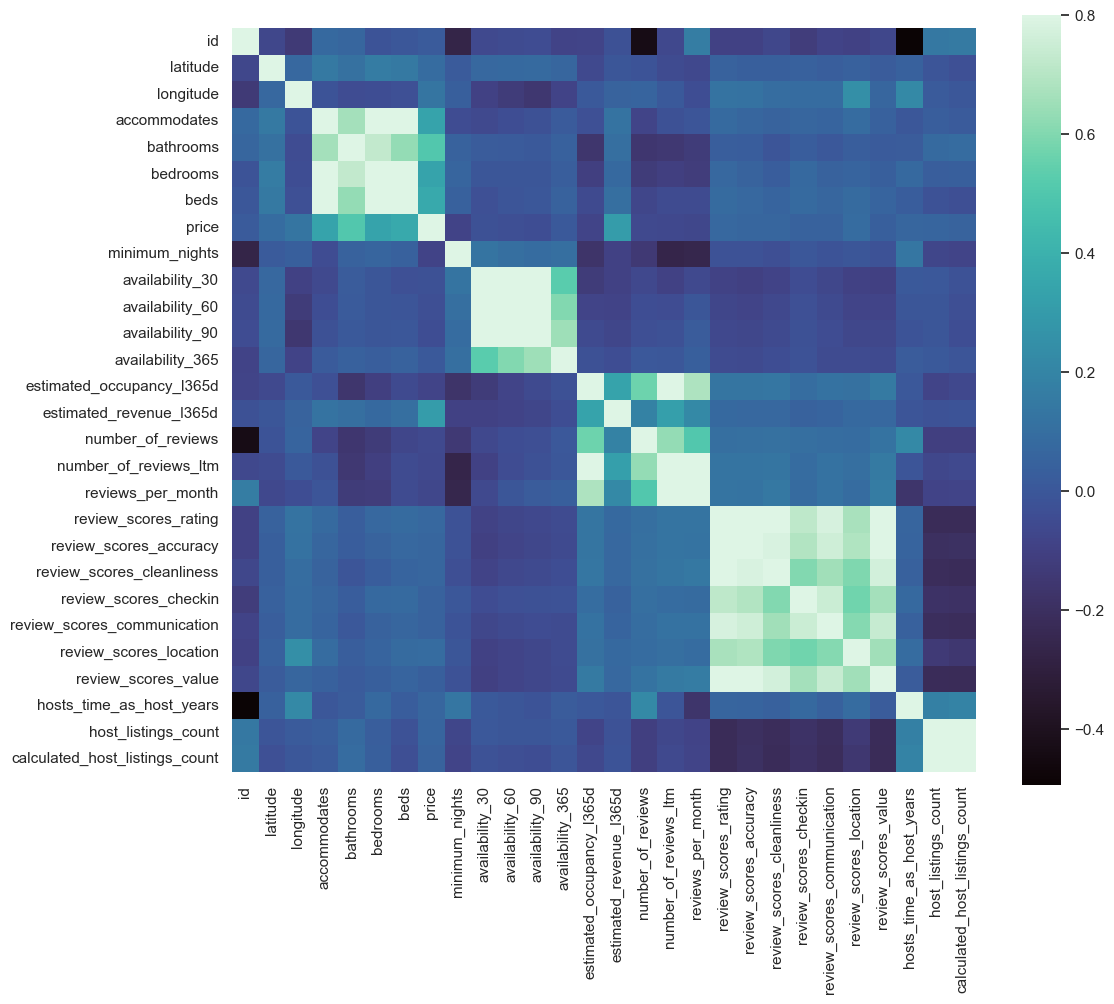

In [53]:
# correlation between every pair of numeric columns, as one big heatmap
# vmax=0.8 caps the colour scale so the strongest links stand out clearly
plt.figure(figsize=(12,10))
sns.heatmap(numeric_features.corr(), square=True, vmax=0.8, cmap='mako')

The heatmap is the best way to get a quick overview of correlated features thanks to seaborn!

The 'availability' columns clearly move together, and so do the size columns ('accommodates', 'bedrooms', 'beds'). These variables give (almost) the same information, and hence it's a case of [multicollinearity](https://en.wikipedia.org/wiki/Multicollinearity). In ML problems related to feature selection these heatmaps provide an excellent exploratory tool.

<Axes: >

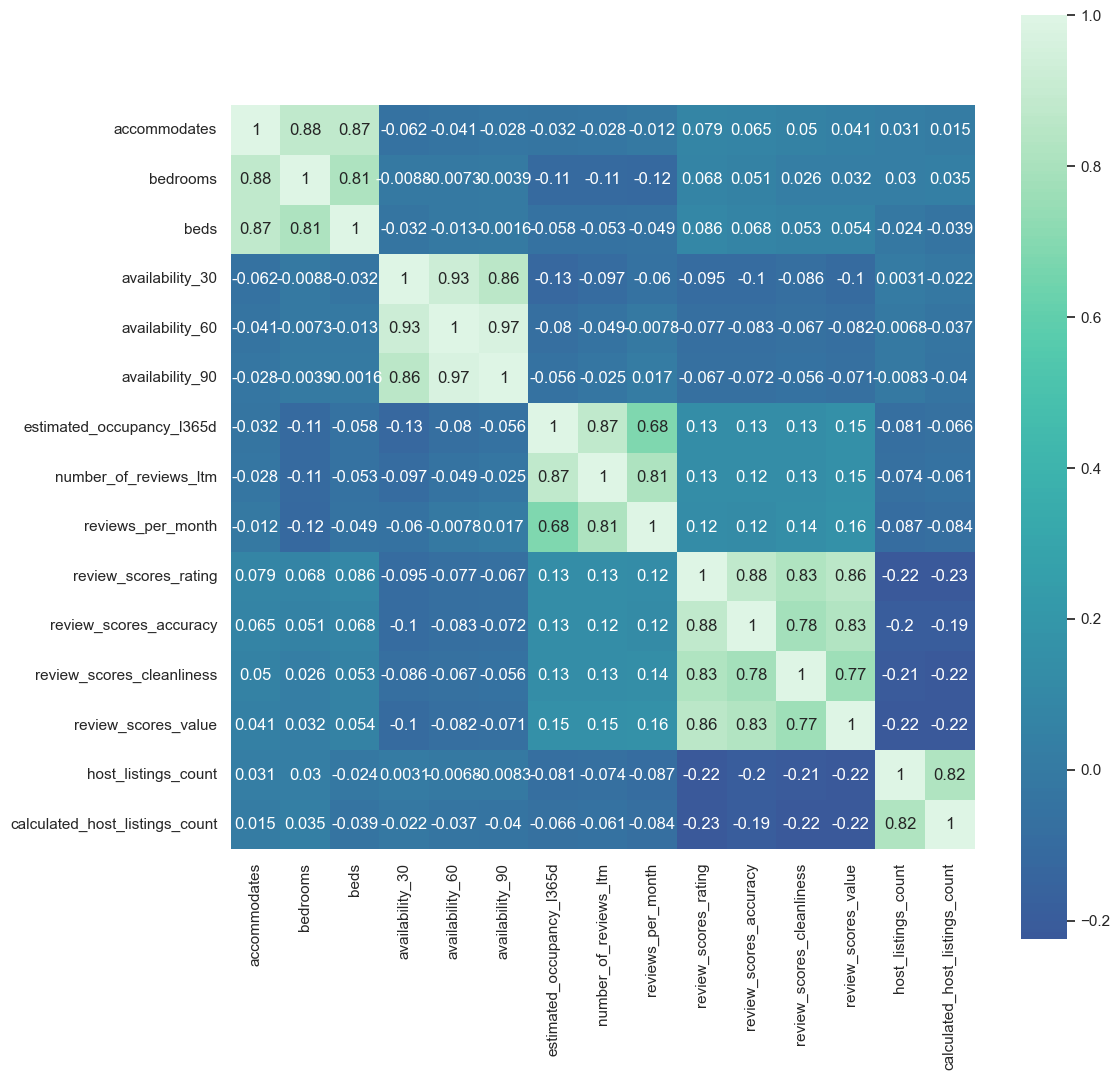

In [54]:
# zoom in on just the strongly related columns
plt.figure(figsize=(12,12))
corr = numeric_features.corr()

# Keep only columns that are strongly correlated (>0.8) with at least one other column
# (every column counts itself once - its self-correlation is 1.0 - so "> 1"
#  means "correlated with at least one column besides itself")
high_corr_columns = corr.columns[(corr > 0.8).sum() > 1]

# annot=True prints the correlation value inside each square
sns.heatmap(corr.loc[high_corr_columns, high_corr_columns],
            square=True, center=0, annot=True, cmap='mako')

To understand the code of `corr.columns[(corr > 0.8).sum() > 1]` I will display 4 columns. The first 3 are highly correlated, the last one is not. It can be seen how the first 3 columns have values greater than 0.8 in at least one row, while the last column has no values greater than 0.8 in any other row (excluding with itself).

In [55]:
display(corr[['accommodates', 'bedrooms', 'beds', 'latitude']].head(10))

,accommodates,bedrooms,beds,latitude
id,0.075259,-0.017315,-0.001428,-0.073978
latitude,0.143321,0.159217,0.145853,1.000000
longitude,-0.015057,-0.041684,-0.033206,0.071813
accommodates,1.000000,0.879537,0.872992,0.143321
bathrooms,0.660861,0.725939,0.632816,0.108742
bedrooms,0.879537,1.000000,0.808719,0.159217
beds,0.872992,0.808719,1.000000,0.145853
price,0.338285,0.336812,0.364545,0.091884
minimum_nights,-0.046301,0.061232,0.039451,0.011597
availability_30,-0.061819,-0.008801,-0.031669,0.068861


In [56]:
(corr > 0.8).sum()

id                                1
latitude                          1
longitude                         1
accommodates                      3
bathrooms                         1
bedrooms                          3
beds                              3
price                             1
minimum_nights                    1
availability_30                   3
availability_60                   3
availability_90                   3
availability_365                  1
estimated_occupancy_l365d         2
estimated_revenue_l365d           1
number_of_reviews                 1
number_of_reviews_ltm             3
reviews_per_month                 2
review_scores_rating              4
review_scores_accuracy            3
review_scores_cleanliness         2
review_scores_checkin             1
review_scores_communication       1
review_scores_location            1
review_scores_value               3
hosts_time_as_host_years          1
host_listings_count               2
calculated_host_listings_cou

- 'accommodates', 'bedrooms' and 'beds' are strongly correlated. How many people a listing sleeps is a consequence of how many bedrooms and beds it has — they are like twin brothers (triplets, really). So it is hard to distinguish between them, and we would need only one of these in our analysis.
- 'availability_30', 'availability_60' and 'availability_90' are twins by construction: a night that is free in the next 30 days is also free in the next 60 and 90.
- 'estimated_occupancy_l365d', 'number_of_reviews_ltm' and 'reviews_per_month' move together — the occupancy estimate is calculated from recent reviews, so they are related by definition.
- The review sub-scores ('accuracy', 'cleanliness', 'value') all track the overall 'review_scores_rating': a guest who liked the stay tends to score everything highly.
- 'host_listings_count' and 'calculated_host_listings_count' are two ways of counting the same thing.

<h3>Pair Plot</h3>
Pair Plots between 'price' and interesting variables <br />
Visualisation of 'accommodates','bedrooms','beds','estimated_revenue_l365d','review_scores_rating','hosts_time_as_host_years','number_of_reviews' features with respect to price in the form of pair plot & scatter pair plot to create better understanding.

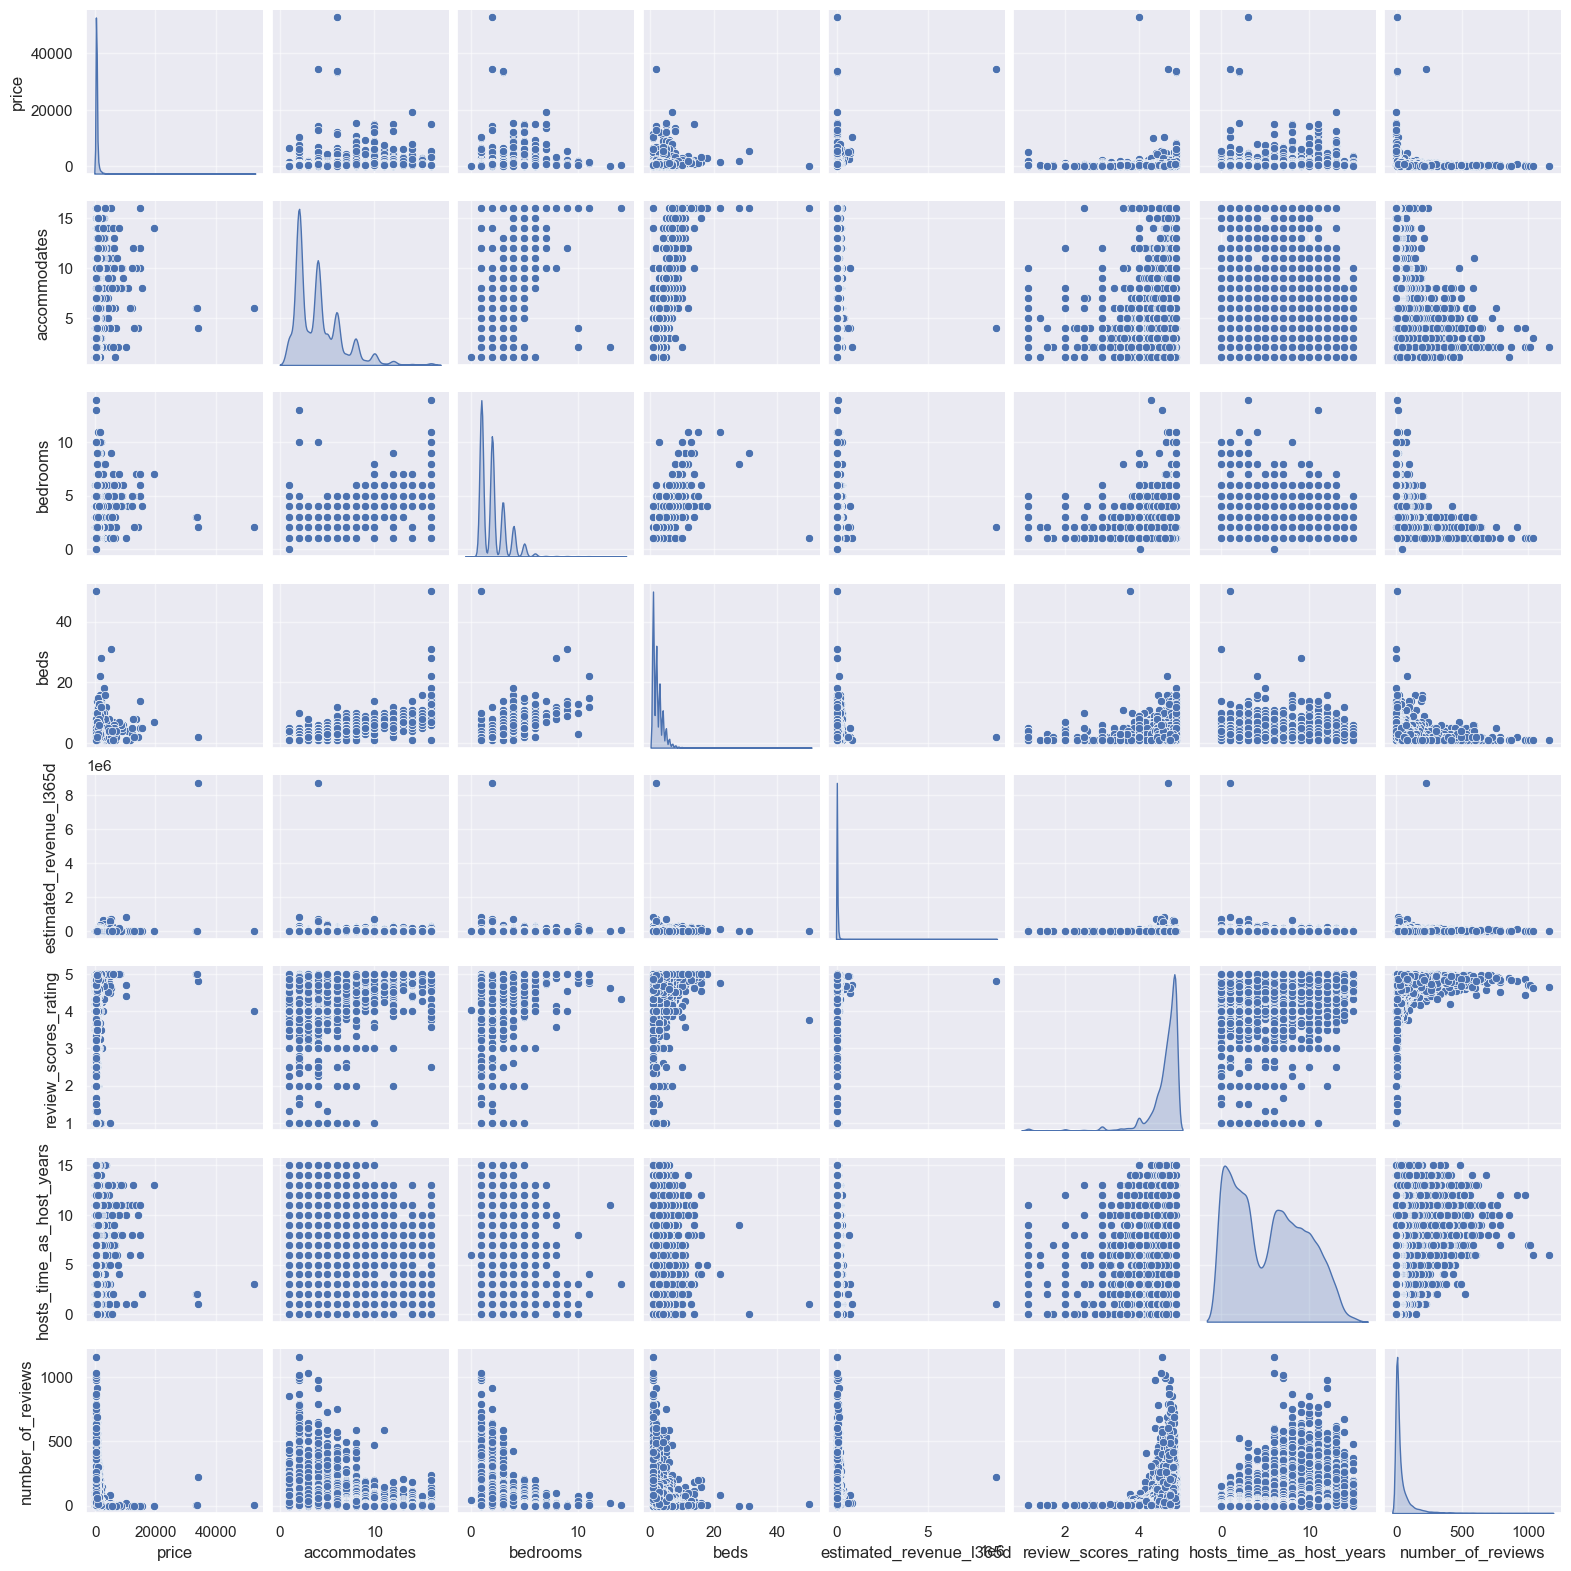

In [57]:
# pair plot: every chosen column plotted against every other
# scatter charts off the diagonal show relationships between pairs;
# the smooth curves on the diagonal show each column's own distribution
# (patience - this one draws over a million points, so it takes a little while)
sns.set_theme()
columns = ['price','accommodates','bedrooms','beds','estimated_revenue_l365d','review_scores_rating','hosts_time_as_host_years','number_of_reviews']
sns.pairplot(df[columns], height=2, kind='scatter', diag_kind='kde')

<h1>What did we find?</h1>

Reading the price row: size is what moves it — 'accommodates' and 'bedrooms' (≈ 0.34 each) are the strongest links, with estimated revenue close behind. Just as interesting is what does <i>not</i> move it: 'review_scores_rating' correlates with price at only ≈ 0.07 — guests rate cheap stays about as highly as expensive ones. We also found multicollinearity in five separate families — the size trio, the availability windows, the review-activity columns, the review sub-scores, and the two host-listing counts — so a model would need only one column from each family. And several columns have missing values that would need treatment before modelling: listings with no reviews yet have no scores (nothing sensible to impute — the feature does not exist yet), while 'bathrooms' and 'beds' are simply unrecorded for some listings (candidates for imputation).

## Extra: plotting the location

[Plotly documentation](https://plotly.com/python/tile-scatter-maps/)

In the map below the outliers really mess up with the price:

In [58]:
import plotly.express as px

# Exclude listings with missing coordinates
map_df = df.dropna(subset=['latitude', 'longitude', 'price'])

fig = px.scatter_map(
    map_df,
    lat='latitude',
    lon='longitude',
    map_style='open-street-map',
    zoom=10,
    opacity=0.5,
    height=650,
    title='Sydney Airbnb locations',
    color='price',
)

fig.show()

In [59]:
from IPython.display import display, Markdown

low_percentile = 10
high_percentile = 90

display(Markdown(
    f"Here the price is grouped into three categories: **low, typical and high**. "
    f"The low and high groups are defined by percentile **{low_percentile}** "
    f"and percentile **{high_percentile}** of the price distribution. "
    f"The typical group is everything in between."
))

Here the price is grouped into three categories: **low, typical and high**. The low and high groups are defined by percentile **10** and percentile **90** of the price distribution. The typical group is everything in between.

In [60]:
map_df = map_df.copy()


low = map_df['price'].quantile(low_percentile / 100)
high = map_df['price'].quantile(high_percentile / 100)

map_df['price_group'] = pd.cut(
    map_df['price'],
    bins=[float('-inf'), low, high, float('inf')],
    labels=['Low price', 'Typical price', 'High price'],
)

fig = px.scatter_map(
    map_df,
    lat='latitude',
    lon='longitude',
    color='price_group',
    hover_data=['price'],  # Keep the actual price visible
    category_orders={
        'price_group': ['Low price', 'Typical price', 'High price']
    },
    color_discrete_map={
        'Low price': 'blue',
        'Typical price': 'gray',
        'High price': 'red',
    },
    map_style='open-street-map',
    zoom=10,
    opacity=0.6,
    height=650,
    title='Sydney Airbnb price groups',
)

fig.show()

In [61]:
display(Markdown(
    f"The code below caps the prices used for colouring so that extreme values "
    f"don't distort the colour scale. The actual prices are still visible "
    f"in the hover data, but the colour scale is capped at percentile "
    f"**{low_percentile}** and percentile **{high_percentile}**."
))

The code below caps the prices used for colouring so that extreme values don't distort the colour scale. The actual prices are still visible in the hover data, but the colour scale is capped at percentile **10** and percentile **90**.

In [62]:
# Cap only the values used for colouring; preserve actual prices
map_df['price_colour'] = map_df['price'].clip(lower=low, upper=high)

fig = px.scatter_map(
    map_df,
    lat='latitude',
    lon='longitude',
    color='price_colour',
    range_color=[low, high],
    color_continuous_scale='Viridis',
    hover_data={'price': ':,.2f', 'price_colour': False},
    map_style='open-street-map',
    zoom=10,
    opacity=0.6,
    height=650,
    title='Sydney Airbnb prices',
)

ticks = np.linspace(low, high, 5)
tick_labels = [f'${value:,.0f}' for value in ticks]
tick_labels[0] = f'≤ ${low:,.0f}'
tick_labels[-1] = f'≥ ${high:,.0f}'

fig.update_layout(
    coloraxis_colorbar=dict(
        title='Price',
        tickvals=ticks,
        ticktext=tick_labels,
    )
)

fig.show()